# <center>🔤 Лекция 7. Большие языковые модели и промпт-инжиниринг</center>
## <center>大语言模型与提示词工程</center>

### <center>Прикладные технологии искусственного интеллекта</center>
#### <center>Модуль 4 — Основные сценарии применения ИИ · 2 академических часа (90 минут)</center>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цели лекции:</b><br>
1. объяснять весь путь: текст → токены → эмбеддинги → вероятности следующего токена → генерация;<br>2. описывать устройство трансформера на уровне идей: внимание, блоки, окно контекста;<br>3. называть три стадии обучения LLM (предобучение, SFT, RLHF) и их результаты;<br>4. ориентироваться в карте моделей: GPT/Claude/Gemini и DeepSeek/Qwen/Kimi/GLM/ERNIE/Hunyuan;<br>5. составлять сильные промпты по формуле «роль + контекст + задача + формат (+ примеры)» и улучшать их итерациями;<br>6. понимать температуру, галлюцинации и правила безопасного использования.
</div>

<div style='background-color: #FFF3E0; padding: 12px; border-left: 5px solid #FB8C00; margin: 20px 0;'>
<b>⏱️ План работы (90 минут):</b><br>
• Текст → токены → эмбеддинги <i>(15 мин)</i><br>• Предсказание следующего токена и генерация <i>(15 мин)</i><br>• Трансформер и внимание — по идеям <i>(15 мин)</i><br>• Три стадии обучения LLM <i>(10 мин)</i><br>• Карта моделей: мир и Китай <i>(10 мин)</i><br>• Промпт-инжиниринг: практика <i>(20 мин)</i><br>• Галлюцинации и правила безопасности <i>(10 мин)</i><br>• Мини-тест и итоги <i>(5 мин)</i>
</div>

<div style='background-color: #E3F2FD; padding: 12px; border-left: 5px solid #1976D2; margin: 20px 0;'>
<b>📦 Что понадобится:</b> OpenAI SDK (для GLM/DeepSeek/Qwen), jieba, scikit-learn.
</div>

<div style='background-color: #FCE4EC; padding: 12px; border-left: 5px solid #C2185B; margin: 20px 0;'>
<b>💡 Как работать с ноутбуком.</b> Теория читается сверху вниз; все рисунки уже внедрены в файл — внешние контейнеры и сетка не нужны. Демонстрационные ячейки с кодом можно запускать по порядку.
</div>


In [ ]:
# Настройка ноутбука: графики внутри документа, кириллица и иероглифы
%matplotlib inline
import numpy as np
import matplotlib.font_manager as fm
import os
for fp in ['/usr/share/fonts/truetype/chinese/NotoSansSC-Regular.ttf']:
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Настройка завершена. Запускайте ячейки по порядку — сверху вниз.')

Настройка завершена. Запускайте ячейки по порядку — сверху вниз.


## 1. Как текст становится числами (и смыслами)

### 1.1. Токенизация

LLM не читает буквы и не знает слов. Текст режется на **токены** — кусочки, найденные в словаре:


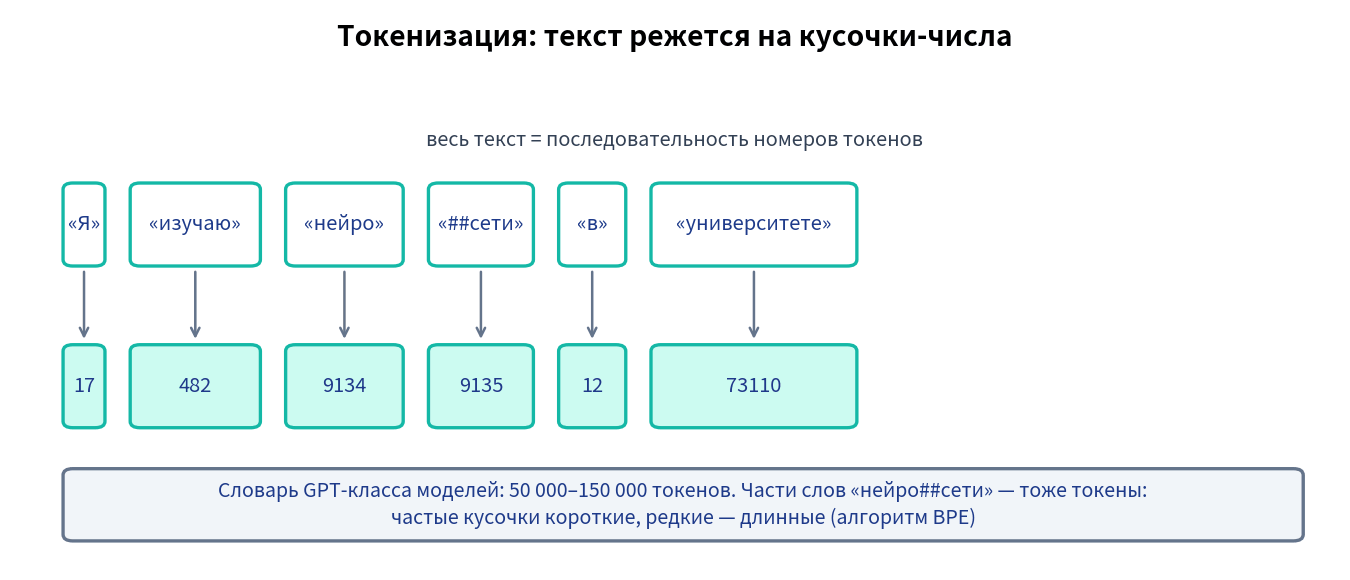

BPE (Byte-Pair Encoding) собирает словарь так: самые частые пары символов склеиваются в кусочки («не», «##сет», «ing»), редкие остаются длинными. Отсюда наблюдение, знакомое по чекам за API: **стоимость измеряется в токенах**, и русский текст «дороже» английского — кириллица режется на более мелкие кусочки.

### 1.2. Эмбеддинги: слова становятся точками

Каждый токен получает вектор из сотен чисел — **эмбеддинг** (词向量). Важное свойство: близкие по смыслу слова оказываются рядом:


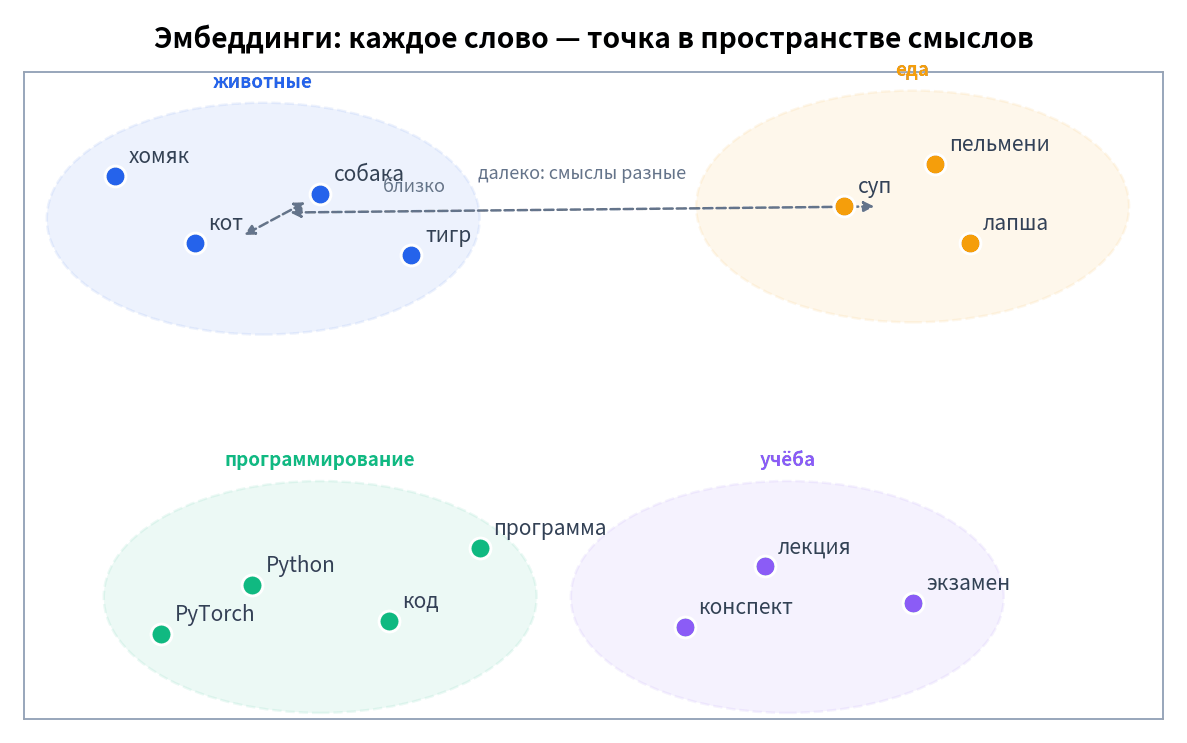

Это не магия, а следствие обучения: слова, встречающиеся в похожих контекстах, получают похожие векторы («кот» и «хомяк» окружены одними и теми же глаголами). Эмбеддинги — тот самый мост «смысл → геометрия»: расстояние и угол между векторами несут смысл. Поисковики и рекомендательные системы живут именно на этом.

**Знаменитая иллюстрация**: вектор(король) − вектор(мужчина) + вектор(женщина) ≈ вектор(королева). Направения в пространстве слов кодируют отношения.


In [ ]:
# Мини-эмбеддинги своими руками: bag-of-words по маленькому корпусу
docs = ["кот ест рыбу", "хомяк ест зерно", "кот спит на диване",
        "студент читает конспект", "студент сдаёт экзамен"]
vocab = sorted({w for d in docs for w in d.split()})
def embed(text):
    v = np.zeros(len(vocab))
    for w in text.split():
        v[vocab.index(w)] += 1
    return v

cos = lambda a, b: a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
print("слова в словаре:", len(vocab))
print(f"похожесть «кот ест рыбу» и «хомяк ест зерно»:  cos = {cos(embed(docs[0]), embed(docs[1])):.2f}")
print(f"похожесть «кот ест рыбу» и «студент сдаёт экзамен»: cos = {cos(embed(docs[0]), embed(docs[4])):.2f}")

слова в словаре: 13
похожесть «кот ест рыбу» и «хомяк ест зерно»:  cos = 0.33
похожесть «кот ест рыбу» и «студент сдаёт экзамен»: cos = 0.00


## 2. Главная задача LLM: угадать следующий токен

Всё, что делает ChatGPT или DeepSeek, — **очень мощное «автодополнение»**. Дан контекст; модель выдаёт распределение вероятностей следующего токена:


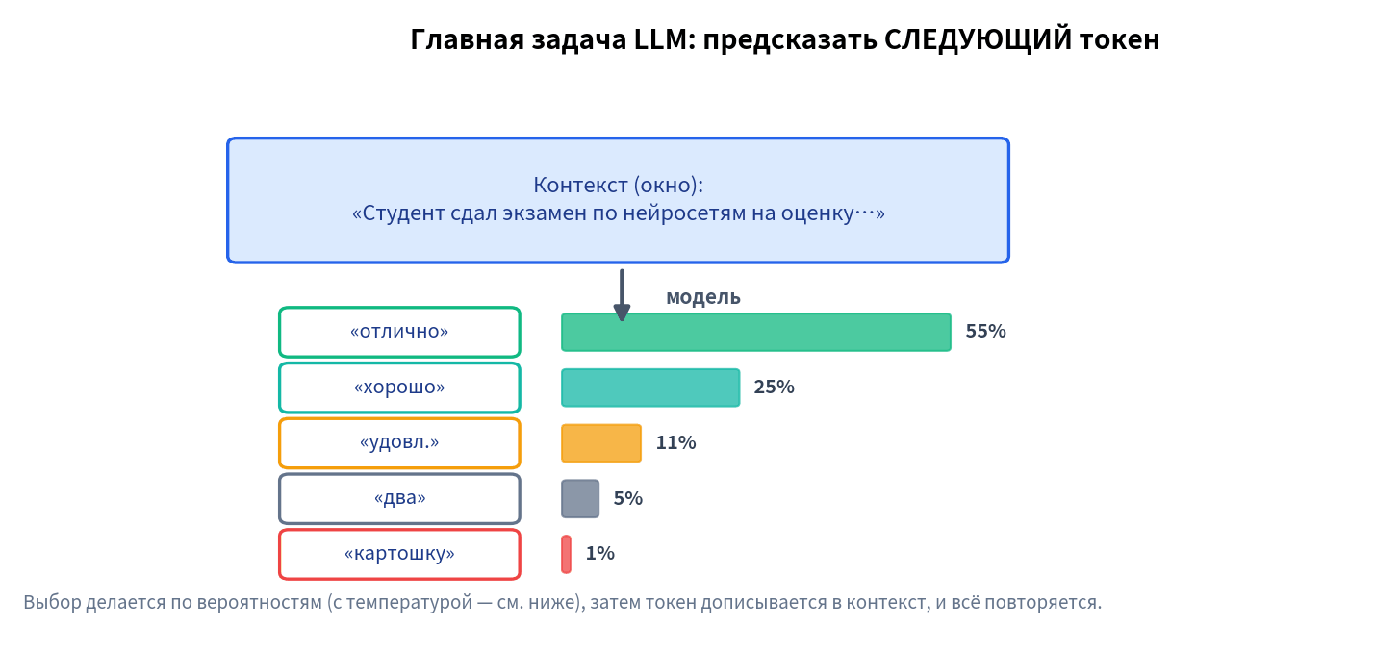

Генерация ответа — цикл: выбрали токен → дописали к контексту → снова вероятности → … → пока не токен «конец». Отсюда, кстати, «характерная походка» LLM-ошибок: модель не может вернуться и зачеркнуть сказанное — она печатает вслепую, токен за токеном.

### 2.1. Температура: ручка «творчества»


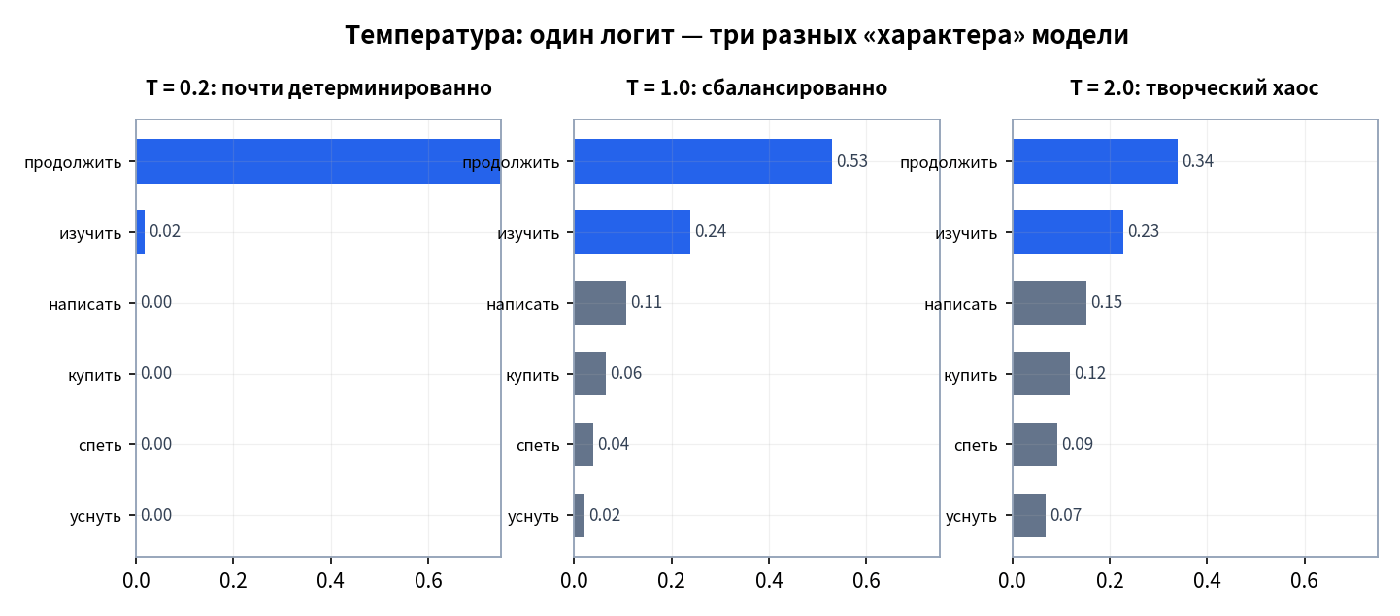

$$p_i = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}$$

При $T \to 0$ выбирается всегда самый вероятный токен (факты, код, экзамены); при $T \approx 1$ — сбалансированно; при $T > 1.5$ распределение выравнивается — появляется неожиданность (иногда гениальная, чаще бредовая). Настройка в API — первая ручка, которую стоит крутить осознанно.


In [ ]:
# Температура на numpy: одни и те же логиты, три характера
logits = np.array([2.2, 1.4, 0.6, 0.1, -0.4, -1.0])
for T in [0.2, 1.0, 2.0]:
    p = np.exp(logits / T); p /= p.sum()
    print(f"T={T:4.1f}: ", np.round(p, 3))

T= 0.2:  [0.982 0.018 0.    0.    0.    0.   ]
T= 1.0:  [0.529 0.238 0.107 0.065 0.039 0.022]
T= 2.0:  [0.34  0.228 0.153 0.119 0.093 0.069]


---
## 🎬 Видеоматериалы: токены и эмбеддинги
Видео к разделам 1–2 лекции: как текст превращается в числа (токены, векторы слов, языковое моделирование).
### 🇷🇺 РУС · русскоязычные видео (1)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [ML #16. Байесовский вывод. Наивная байесовская классификация](https://rutube.ru/video/36a3876261166551575f83970344402a/) | Rutube · SelfEdu | 10 мин | П8: наивный Байес — классификатор текстов  X |
### 🇨🇳 中文 · китайскоязычные видео (оригинал в курсиве) (2)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [От эмбеддингов слов к RNN](https://www.bilibili.com/video/BV1DgxCzREbM?p=5)<br>· ориг.: *【入门篇】从词嵌入到 RNN* | Bilibili (анимакурс) | 9 мин | Л7 §1: текст становится числами  ✓ |
| 2 | [Основы NLP: представления слов и языковые модели](https://www.bilibili.com/video/BV1UG411p7zv?p=5)<br>· ориг.: *1-5 自然语言处理基础--词表示与语言模型* | Bilibili · 清华NLP | 24 мин | Л7 §1–2: эмбеддинги и языковое моделирование  ✓ |
### 🇬🇧 EN · англоязычные видео (1)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [StatQuest:词嵌入 word2vec — слова как векторы](https://www.bilibili.com/video/BV1Km421u7uu/)<br>· ориг.: *【官方双语】词嵌入、word2vec模型，如何将文字转化为数值，超清晰解释！* | Bilibili · StatQuest | 16 мин | Л7 §1.2: эмбеддинги слов  ✓ |

> 📄 Полная версия с идентичными ссылками: PDF «Видеоматериалы по 5 модулям и 10 лекциям», глава соответствующего модуля.

## 3. Трансформер: конвейер из блоков внимания

Архитектура всех современных LLM (статья «Attention Is All You Need», 2017):


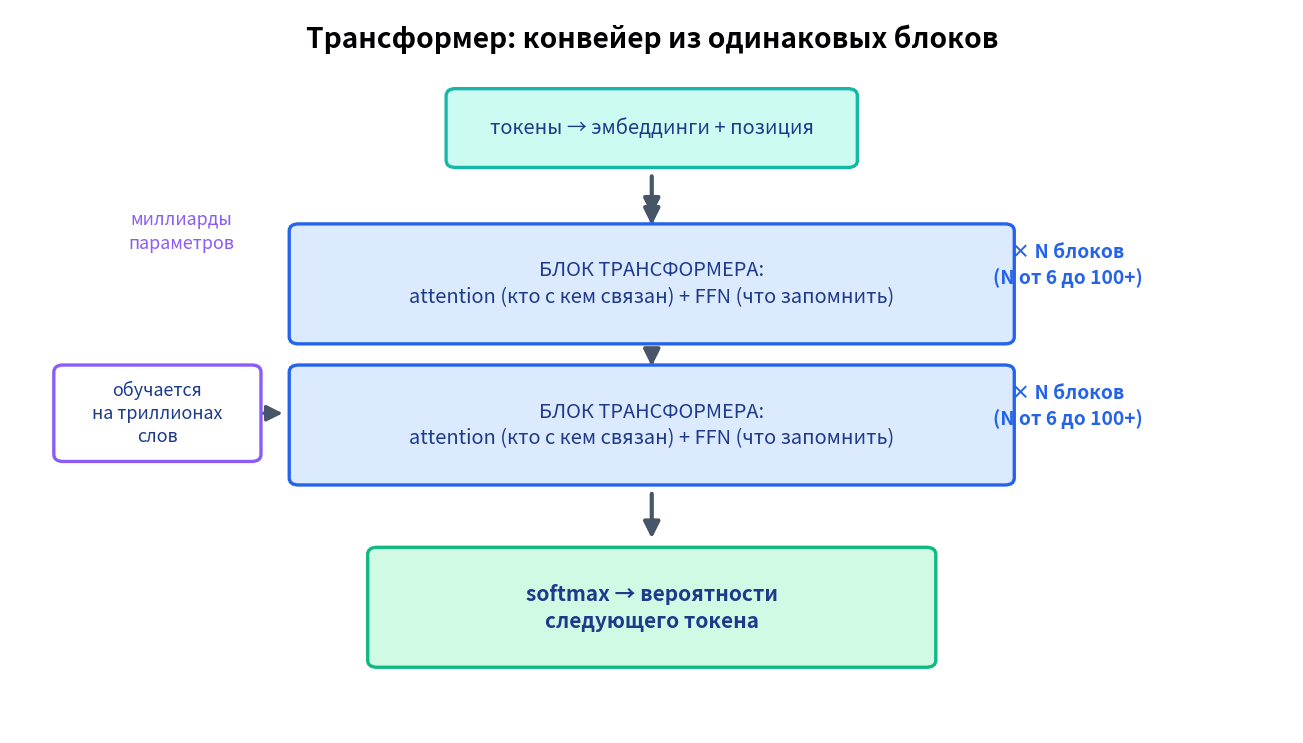

Ключевая операция — **внимание** (attention, 注意力): каждый токен «смотрит» на все предыдущие и набирает от каждого вес-важность:


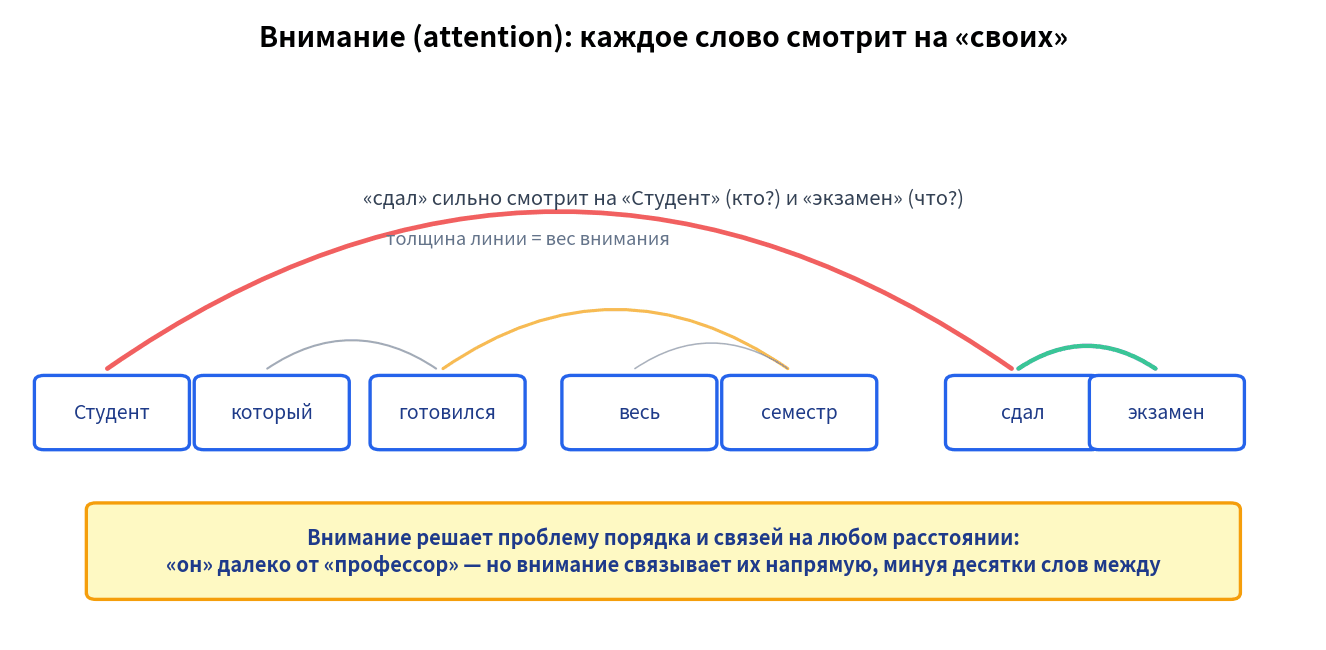

Три следствия, которые стоит понять:

1. **Дальность связей не важна**: «он» связывается с «профессор» через 40 слов напрямую, а не по цепочке — рекуррентные сети 2010-х этого не умели.
2. **Всё считается параллельно** → GPU загружены идеально → можно обучать на триллионах слов.
3. **Окно контекста** (context window) — сколько токенов модель «держит в голове»: от 4–8 тыс. у ранних моделей до сотен тысяч и миллионов у новых. За окном — «слепая зона»: о чём модель не помнит вообще.

Параметры — это веса всех блоков: у мобильных моделей 1–8 млрд, у флагманов — сотни миллиардов. Отсюда и возможности, и стоимость обучения.


## 4. Как «начитанный автокомплит» становится помощником

Три стадии — и это самая недооценённая часть рассказа про ChatGPT:


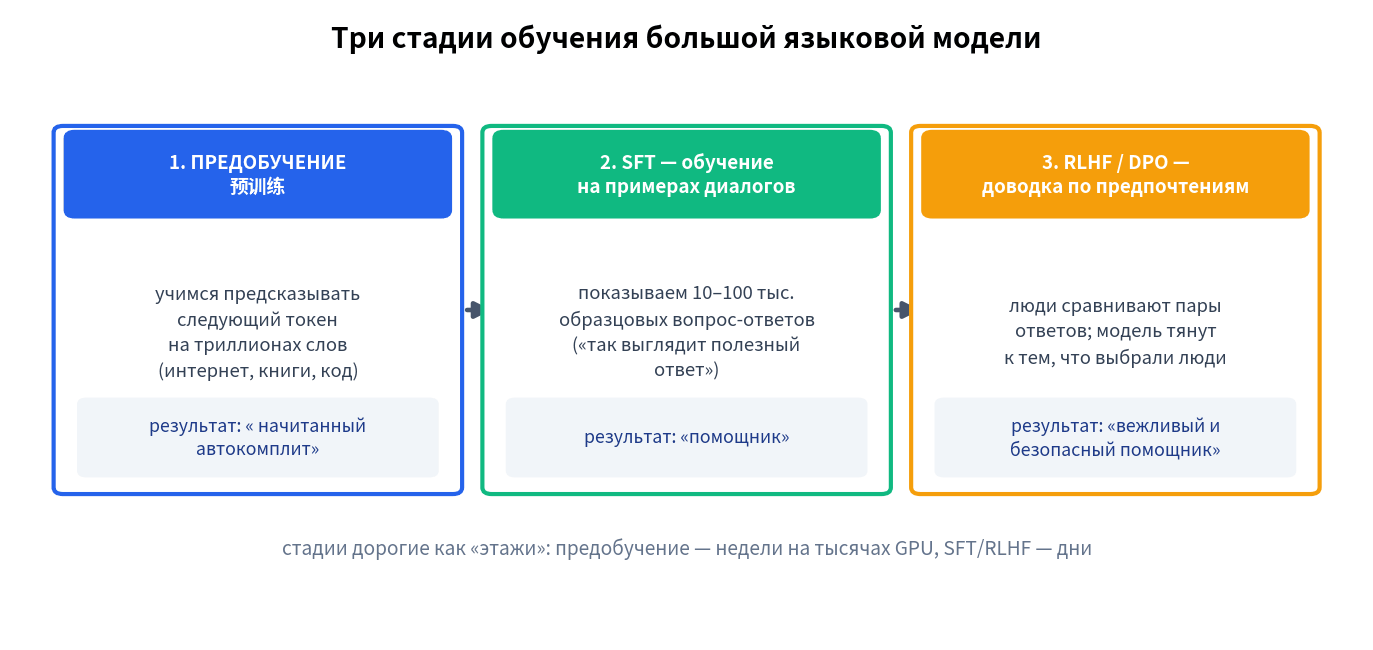

**Предобучение** (могут позволить себе единицы компаний): недели на тысячах GPU, триллионы слов из интернета. Результат знает факты и стили, но ведёт себя как странный автокомплит — на вопрос отвечает новыми вопросами.

**SFT** (supervised fine-tuning): люди пишут 10–100 тысяч образцовых диалогов; модель доучивается «как выглядит полезный ответ». Появляется поведение ассистента.

**RLHF/DPO**: людям показывают пары ответов — «какой лучше?»; модель подтягивают к предпочтениям. Так появляются вежливость, осторожность, отказы от вредного. У DeepSeek-R1 добавилась ещё ступень «рассуждение с подкреплением по правильности ответа» — модель учится думать цепочками перед ответом.


## 5. Карта моделей: мир и Китай


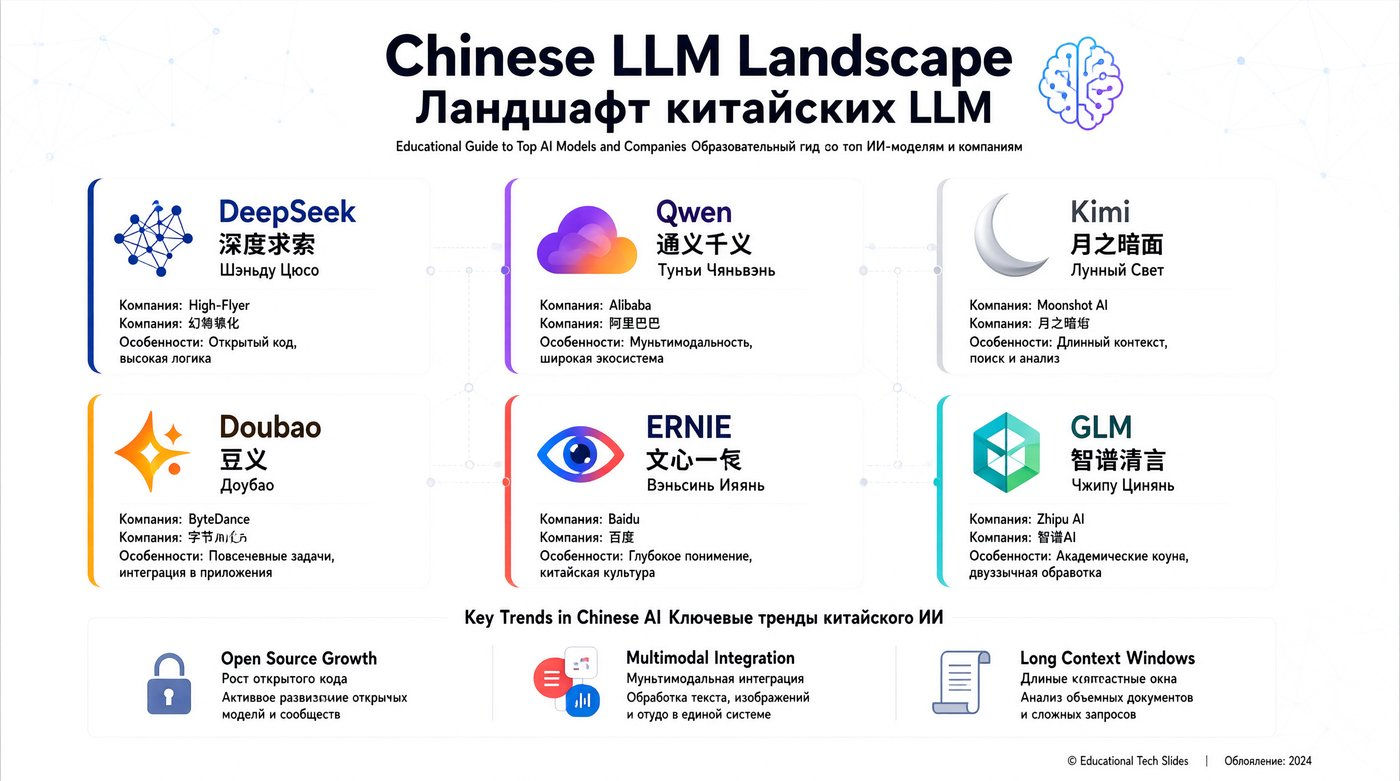

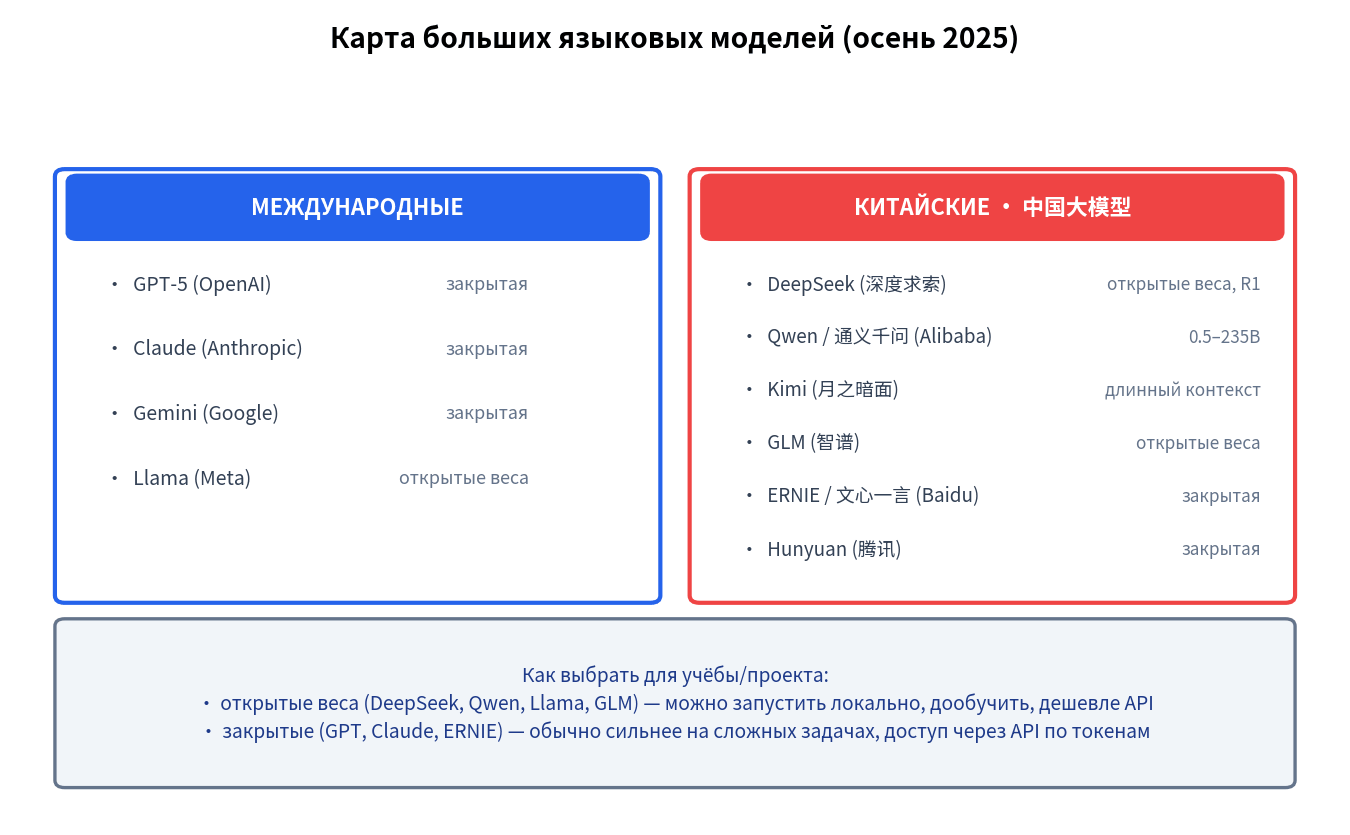

Для проекта курса (практика 8) логика выбора: экспериментируете с открытыми моделями через библиотеку `transformers` (Hugging Face) или API; для студентов в КНР внутренние модели часто доступны быстрее и дешевле. Список моделей устаревает за месяцы — сверяйтесь с открытыми лидербордами (LMSYS Arena, Open LLM Leaderboard, SuperCLUE для китайских).



### ⚖️ Что физически означает «модель на 70 миллиардов параметров»?

Параметр — это **один вес связи** внутри сети, то же самое, что $w$ в нейроне из лекции 5. Семьдесят миллиардов таких чисел, подобранных градиентным спуском, — «плотность знаний» модели.

Для контраста: в нашей учебной CNN на MNIST — около **полумиллиона** параметров, и обучается она за минуты на ноутбуке. Большая модель учится **неделями на тысячах видеокарт**. Поэтому открытые веса DeepSeek и Qwen так ценны: чужой дорогой труд можно скачать и запускать у себя — бесплатно и без VPN.


---
### 🇷🇺 РУС · русскоязычные видео (4)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [Большие языковые модели — краткое объяснение [3Blue1Brown]](https://vkvideo.ru/video-55155418_456242580)<br>· ориг.: *Large language models explained briefly* | Vert Dider (VK/Rutube) | 7 мин | Л7 §2–4: что такое LLM в 7 минутах  X |
| 2 | [[3Blue1Brown RU] DeepLearning Ч.5. Как работают LLM. Введение в трансформеры](https://rutube.ru/video/82d56c313134463eb833e9e5bdf9d3c7/)<br>· ориг.: *Introduction to Transformers (озвучка Alex_Nik)* | Rutube · Alex_Nik | 27 мин | Л7 §2–3: от автокомплита к GPT  X |
| 3 | [[3Blue1Brown RU] DeepLearning Ч.6. Визуализация внимания](https://rutube.ru/video/a8b9236dfb566c80d4109998b0ba5558/)<br>· ориг.: *Attention in transformers (озвучка Alex_Nik)* | Rutube · Alex_Nik | 26 мин | Л7 §3: Q, K, V внутри блока внимания  X |
| 4 | [[3Blue1Brown RU] DeepLearning Ч.7. Как LLM хранят факты](https://rutube.ru/video/c4e0c62b033b60605656526829a0c5b6/)<br>· ориг.: *How LLMs store facts (озвучка Alex_Nik)* | Rutube · Alex_Nik | 22 мин | Л7 §4: знания внутри параметров  X |

## 6. Промпт-инжиниринг: управление моделью

Модель одна и та же — результат зависит от задания. **Промпт — это ТЗ для очень начитанного, но буквального исполнителя.**

### 6.1. Формула сильного промпта


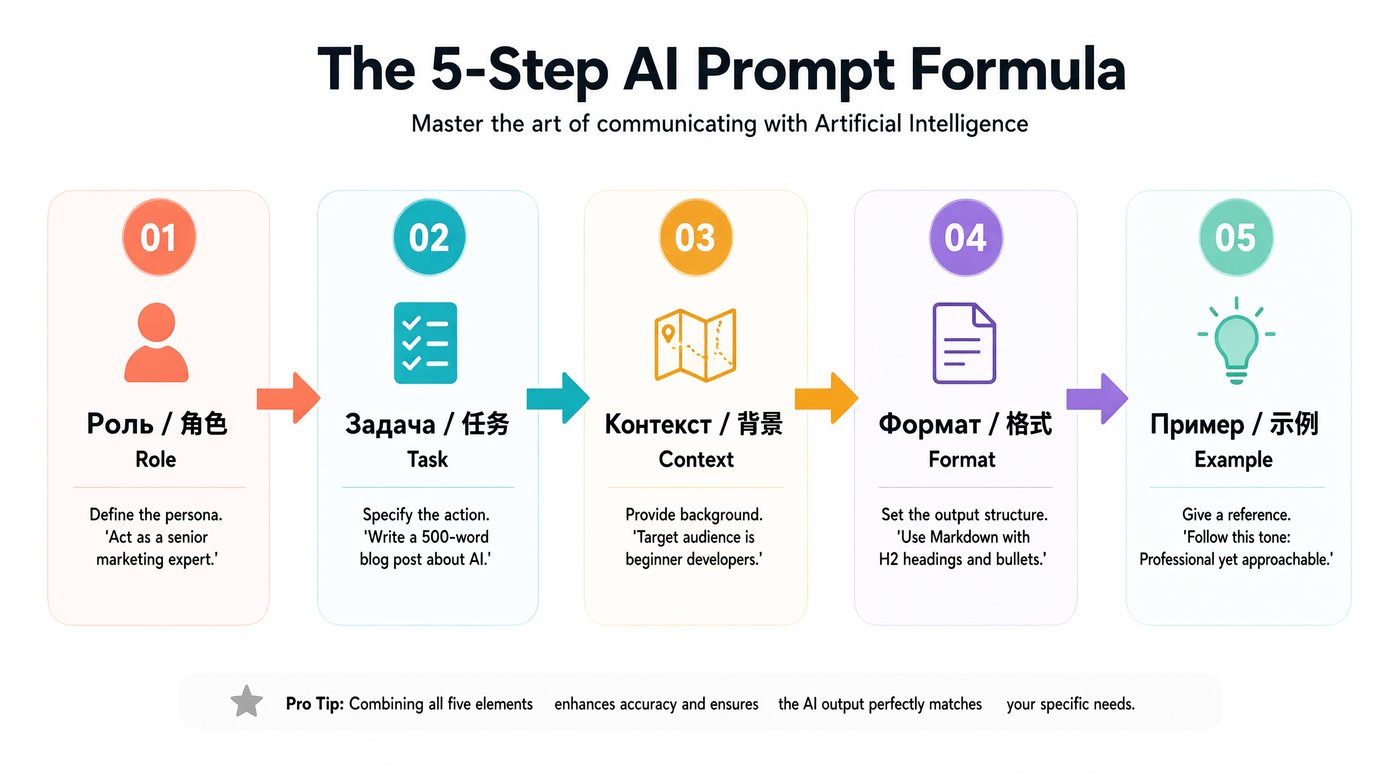

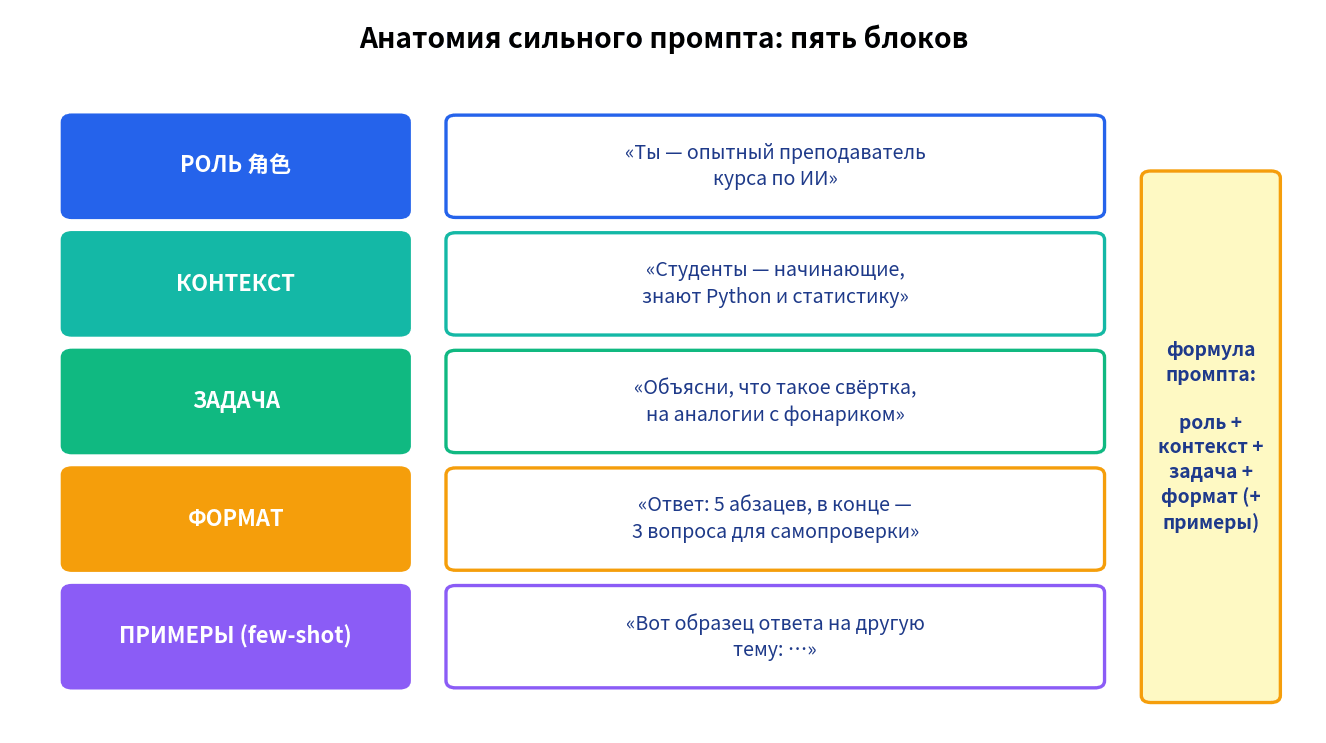


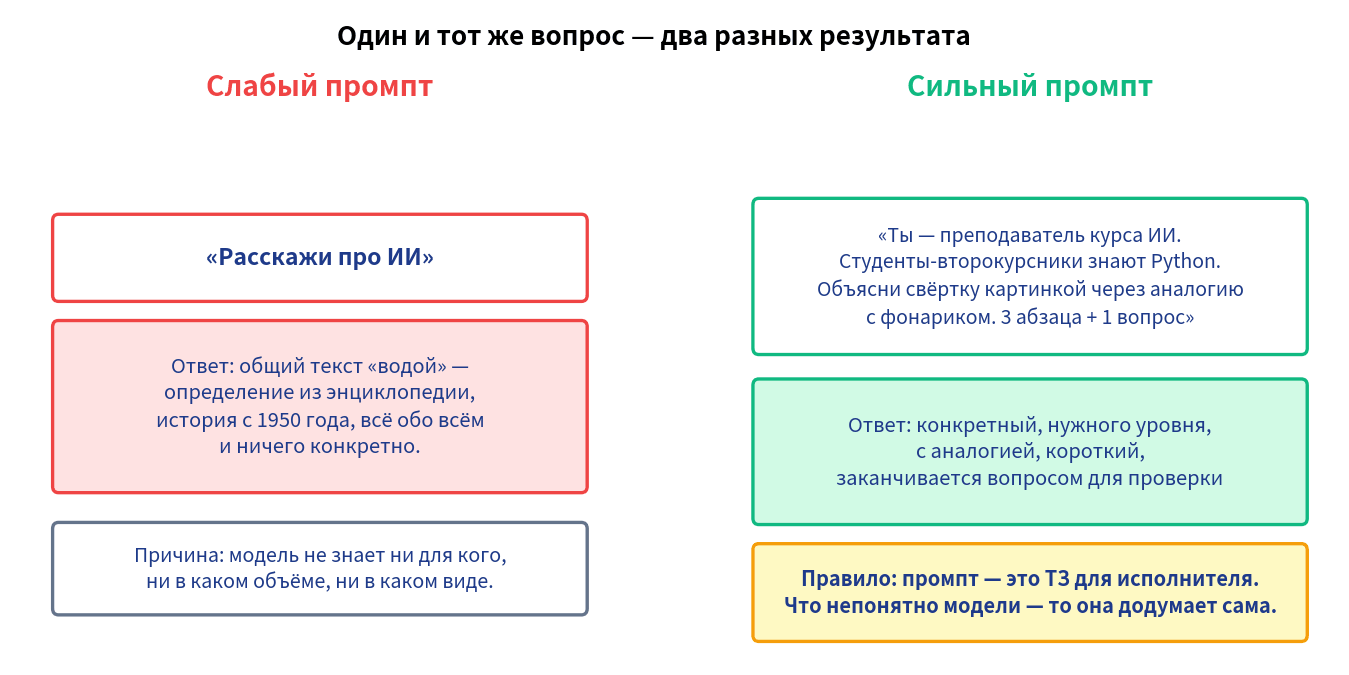

### 6.2. Пять приёмов, закрывающих 80% задач

| Приём | Суть | Пример-заготовка |
|---|---|---|
| **Роль** | задаёт стиль и глубину | «Ты — редактор научных текстов» |
| **Few-shot примеры** | 2–3 образца формата | «вот вход, вот выход; сделай так же» |
| **Цепочка рассуждений (CoT)** | просить думать по шагам | «решай по шагам, в конце — итог одной строкой» |
| **Разбиение задачи** | сложное → список подзадач | «сначала план, потом по пунктам» |
| **Итерации** | промпт — черновик, как код | «что не так в ответе? → уточни промпт → повтори» |

### 6.3. Приём итераций (метод круглых правок)

Промпт редко получается с первого раза — и это нормально. Цикл: написали → получили ответ → **уточнили** («короче», «с примерами из химии», «только таблицу») → повторили. Разница между «ИИ бесполезен» и «ИИ — мой стажёр» обычно равна двум-трём итерациям уточнения.

**❓ Практика прямо сейчас (5 минут):** возьмите любой свой вопрос к LLM и перепишите его по формуле «роль+контекст+задача+формат». Сравните два ответа.



### 🆚 Пример «до / после»: тот же вопрос, разный промпт

**Плохой:** «Напиши про ИИ». → Ответ — общая простыня на две страницы без структуры.

**Хороший:** «Ты — преподаватель курса для первокурсников. Объясни, чем обучение с учителем отличается от обучения без учителя: два абзаца, по одному бытовой аналогии на каждый, в конце — одна строка-вывод». → Ответ ровно такой, как заказано.

Разница не в «магии слов»: в хорошем промпте заданы **роль, аудитория, объём, структура и формат** — вся информация, которой у модели не было.

> ✅ **Самопроверка перед отправкой:** понял бы вашу задачу новый стажёр, которому дали **только этот текст**? Если бы ему пришлось переспрашивать — модель тоже ответит «мимо».


In [ ]:
# Демонстрация "мини-LLM": биграммная модель на маленьком корпусе
corpus = ("студент изучает нейросети студент сдаёт экзамен "
          "нейросети изучают студенты экзамен сдаёт студент "
          "студент любит кофе кофе помогает изучать нейросети").split()
from collections import defaultdict, Counter

next_counts = defaultdict(Counter)
for a, b in zip(corpus, corpus[1:]):
    next_counts[a][b] += 1

def generate(start, n=8, seed=7):
    rng = np.random.default_rng(seed)
    word, out = start, [start]
    for _ in range(n):
        cands = list(next_counts[word].items())
        if not cands: break
        words_, ps = zip(*cands)
        word = rng.choice(words_, p=np.array(ps) / sum(ps))
        out.append(word)
    return " ".join(out)

print("Словарь:", len(set(corpus)), "слов · Старт «студент»:")
for s in [7, 42]:
    print(" ", generate("студент", seed=s))
print("\nНастоящая LLM делает ровно это — но с окном в тысячи токенов и вероятностями,")
print("выученными на триллионах слов.")

Словарь: 11 слов · Старт «студент»:
  студент студент любит кофе кофе кофе помогает изучать нейросети
  студент любит кофе помогает изучать нейросети изучают студенты экзамен

Настоящая LLM делает ровно это — но с окном в тысячи токенов и вероятностями,
выученными на триллионах слов.


## 7. Галлюцинации и правила безопасности


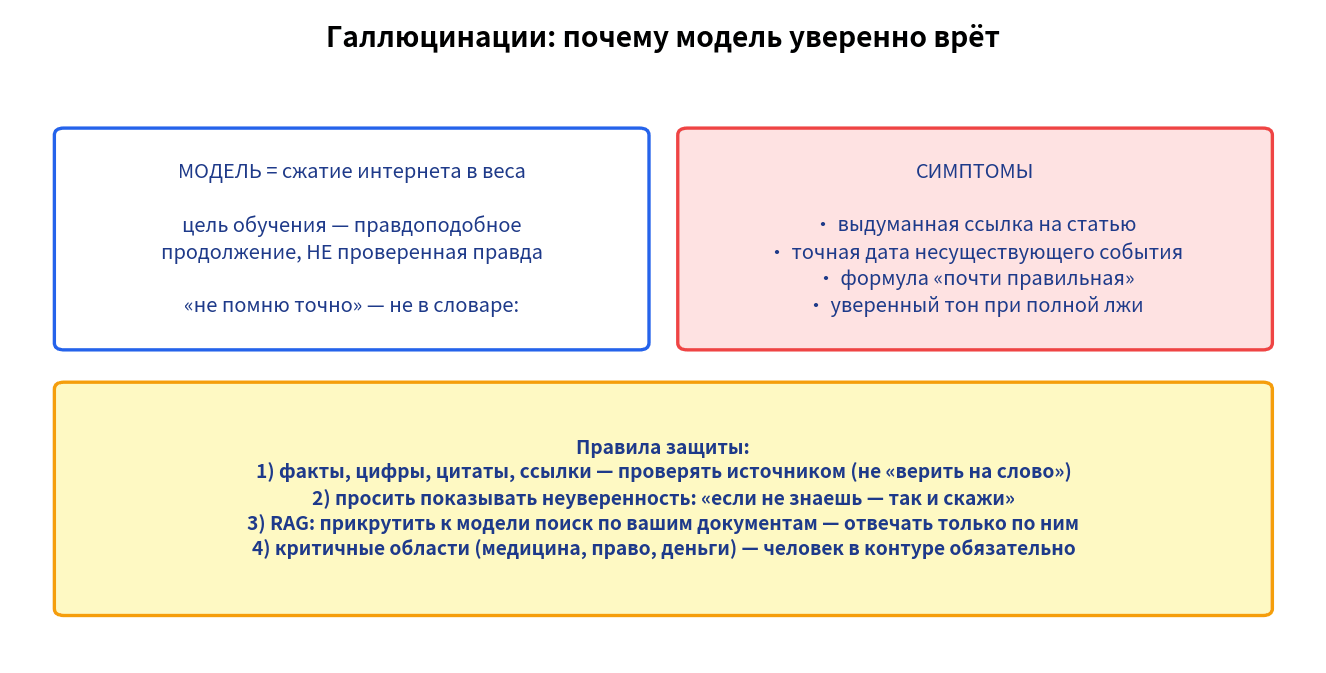

Механика честная: модель оптимизирует **правдоподобие**, а не **истинность**. Если факта нет в весах — модель не «молчит», а достраивает наиболее вероятное продолжение. Отсюда рабочие правила:

1. **Факты — проверять.** Цифры, даты, цитаты, ссылки, законы — только по первоисточнику.
2. **Просить осторожность.** В системный промпт: «если не уверен — скажи прямо, не выдумывай источники».
3. **RAG (Retrieval-Augmented Generation)** — промышленное решение: перед ответом модель получает выдержки из ваших документов и обязана отвечать только по ним. Так делают корпоративные чат-боты по регламентам.
4. **Человек в контуре** — обязательный в медицине, праве, финансах.

И ещё два ограничения, о которых часто забывают: **окно контекста** (длинный документ «не влезает» — модель теряет начало) и **устаревание знаний** (веса зафиксированы в момент обучения; свежие события — только через поиск/RAG).


---
## 🎬 Все видеоматериалы лекции 7

### 🇷🇺 РУС · русскоязычные видео (15)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [Лекция. Векторные представления слов, Bag of Words. Латентный семантический анализ](https://vkvideo.ru/video-155161349_456239180) | VK · DLS-2 | 28:36 | П8 §2: мешок слов; Л7 §1: как текст становится числами · [добавлено] | X |
| 2 | [Лекция. Контестные эмбеддинги. Word2Vec.](https://vkvideo.ru/video-155161349_456239181) | VK · DLS-2 | 29:11 | Л7 §1.2: эмбеддинги — слова становятся точками · [добавлено] | X |
| 3 | [Лекция. Постановка задачи языкового моделирования. Метрики качества](https://vkvideo.ru/video-155161349_456239197) | VK · DLS-2 | 11:06 | Л7 §2: главная задача LLM — угадать следующий токен · [добавлено] | X |
| 4 | [Лекция. Генерация текста с помощью языковых моделей](https://vkvideo.ru/video-155161349_456239200) | VK · DLS-2 | 15:10 | Л7 §2.1: температура — ручка «творчества» · [добавлено] | X |
| 5 | [[3Blue1Brown RU] DeepLearning Ч.5. Как работают LLM. Введение в трансформеры](https://rutube.ru/video/82d56c313134463eb833e9e5bdf9d3c7)<br>· ориг.: *Introduction to Transformers (озвучка Alex_Nik)* | Rutube · Alex_Nik | 27 мин | Л7 §2–3: от автокомплита к GPT | X |
| 6 | [Большие языковые модели — краткое объяснение [3Blue1Brown]](https://vkvideo.ru/video-55155418_456242580)<br>· ориг.: *Large language models explained briefly* | Vert Dider (VK/Rutube) | 7 мин | Л7 §2–4: что такое LLM в 7 минутах | X |
| 7 | [Лекция. Архитектура Transformer. Введение, Transformer Encoder](https://vkvideo.ru/video-155161349_456239220) | VK · DLS-2 | 35:41 | Л7 §3: трансформер — конвейер из блоков внимания · [добавлено] | X |
| 8 | [Лекция. Архитектура Transformer. Decoder, QKV Attention](https://vkvideo.ru/video-155161349_456239221) | VK · DLS-2 | 23:21 | Л7 §3: декодер и QKV-внимание · [добавлено] | X |
| 9 | [Лекция. Механизм внимания (Attention)](https://vkvideo.ru/video-155161349_456239210) | VK · DLS-2 | 30:03 | Л7 §3: механизм внимания · [добавлено] | X |
| 10 | [Py #54. Идея self-attention](https://rutube.ru/video/9aba0242463f45615cd0e50d90ae8ec2) | Rutube · SelfEdu | 12 мин | Л7 §3: само-внимание | X |
| 11 | [Py #55. Трансформеры. QKV Self-Attention](https://rutube.ru/video/08ee029dbe5eb7db700a19be11574fef) | Rutube · SelfEdu | 7 мин | Л7 §3: Q, K, V в коде | X |
| 12 | [[3Blue1Brown RU] DeepLearning Ч.6. Визуализация внимания](https://rutube.ru/video/a8b9236dfb566c80d4109998b0ba5558)<br>· ориг.: *Attention in transformers (озвучка Alex_Nik)* | Rutube · Alex_Nik | 26 мин | Л7 §3: Q, K, V внутри блока внимания | X |
| 13 | [Лекция. GPT-модели - 3. Новые способности и обучение GPT-моделей](https://vkvideo.ru/video-155161349_456239238) | VK · DLS-2 | 35:42 | Л7 §4: как «начитанный автокомплит» становится помощником · [добавлено] | X |
| 14 | [[3Blue1Brown RU] DeepLearning Ч.7. Как LLM хранят факты](https://rutube.ru/video/c4e0c62b033b60605656526829a0c5b6)<br>· ориг.: *How LLMs store facts (озвучка Alex_Nik)* | Rutube · Alex_Nik | 22 мин | Л7 §4: знания внутри параметров | X |
| 15 | [Лекция. Законы масштабирования LLM](https://vkvideo.ru/video-155161349_456239275) | VK · DLS-2 | 41:41 | Л7 §5: карта моделей — законы масштабирования ·  | X |

### 🇨🇳 中文 · китайскоязычные видео (22)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [От эмбеддингов слов к RNN](https://www.bilibili.com/video/BV1DgxCzREbM?p=5)<br>· ориг.: *【入门篇】从词嵌入到 RNN* | Bilibili (анимакурс) | 9 мин | Л7 §1: текст становится числами | ✓ |
| 2 | [Основы NLP: представления слов и языковые модели](https://www.bilibili.com/video/BV1UG411p7zv?p=5)<br>· ориг.: *1-5 自然语言处理基础--词表示与语言模型* | Bilibili · 清华NLP | 24 мин | Л7 §1–2: эмбеддинги и языковое моделирование | ✓ |
| 3 | [Трансформер: входные кодирования (BPE, позиционные)](https://www.bilibili.com/video/BV1UG411p7zv?p=26)<br>· ориг.: *3-6 Transformer结构--输入编码（BPE,PE）* | Bilibili · 清华NLP | 8:38 | Л7 §1: токенизация BPE · [добавлено] | ✓ |
| 4 | [Языковые модели](https://www.bilibili.com/video/BV1EY6FBwE8P?p=154)<br>· ориг.: *154.1-语言模型-* | Bilibili · 李沐 | 16 мин | Л7 §2: предсказание следующего токена | ✓ |
| 5 | [9-1 Примеры последовательных данных](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=46)<br>· ориг.: *9-1 序列数据案例* | Bilibili · Цинхуа ИИ (清华) | 11:42 | Л7 §3: примеры последовательных данных · [добавлено] | ✓ |
| 6 | [RNN — рекуррентные сети](https://www.bilibili.com/video/BV1EY6FBwE8P?p=157)<br>· ориг.: *157.1-RNN-* | Bilibili · 李沐 | 25 мин | Л7 §3: предыстория трансформеров | ✓ |
| 7 | [Простой и мощный Transformer](https://www.bilibili.com/video/BV1DgxCzREbM?p=6)<br>· ориг.: *【入门篇】简单而强大的 Transformer* | Bilibili (анимакурс) | 10 мин | Л7 §3: архитектура трансформера | ✓ |
| 8 | [Механизм внимания](https://www.bilibili.com/video/BV1EY6FBwE8P?p=181)<br>· ориг.: *181.1-注意力机制* | Bilibili · 李沐 | 13 мин | Л7 §3: идея внимания | ✓ |
| 9 | [Механизм внимания: принцип работы](https://www.bilibili.com/video/BV1UG411p7zv?p=22)<br>· ориг.: *3-2 注意力机制--原理介绍* | Bilibili · 清华NLP | 8 мин | Л7 §3: внимание от лица Цинхуа | ✓ |
| 10 | [Внимание: баллы внимания](https://www.bilibili.com/video/BV1EY6FBwE8P?p=183)<br>· ориг.: *183.1-注意力分数* | Bilibili · 李沐 | 10 мин | Л7 §3: внимание до трансформера | ✓ |
| 11 | [Самовнимание (self-attention)](https://www.bilibili.com/video/BV1EY6FBwE8P?p=189)<br>· ориг.: *189.1-自注意力* | Bilibili · 李沐 | 27 мин | Л7 §3: сердце трансформера | ✓ |
| 12 | [Трансформер](https://www.bilibili.com/video/BV1EY6FBwE8P?p=192)<br>· ориг.: *192.1-Transformer* | Bilibili · 李沐 | 21 мин | Л7 §3: конвейер из блоков внимания | ✓ |
| 13 | [Transformer: блок энкодера](https://www.bilibili.com/video/BV1UG411p7zv?p=27)<br>· ориг.: *3-7 Transformer结构--Encoder Block* | Bilibili · 清华NLP | 10 мин | Л7 §3: внутренности блока | ✓ |
| 14 | [Архитектура кодер-декодер](https://www.bilibili.com/video/BV1EY6FBwE8P?p=175)<br>· ориг.: *175.1-编码器-解码器架构* | Bilibili · 李沐 | 3 мин | Л7 §3: перевод и генерация | ✓ |
| 15 | [Seq2Seq](https://www.bilibili.com/video/BV1EY6FBwE8P?p=177)<br>· ориг.: *177.1-Seq2Seq* | Bilibili · 李沐 | 12 мин | Л7 §3: последовательность в последовательность | ✓ |
| 16 | [Transformer: код](https://www.bilibili.com/video/BV1EY6FBwE8P?p=194)<br>· ориг.: *194.3-Transformer代码* | Bilibili · 李沐 | 19 мин | Л7 §3: полный код трансформера | ✓ |
| 17 | [100 слов о больших моделях](https://www.bilibili.com/video/BV1DgxCzREbM?p=7)<br>· ориг.: *【入门篇】速览大模型 100 词* | Bilibili (анимакурс) | 11 мин | Л7 §5: словарь терминов LLM | ✓ |
| 18 | [Prompt-Learning: предыстория и обзор](https://www.bilibili.com/video/BV1UG411p7zv?p=42)<br>· ориг.: *4-2 Prompt-Learning和Delta-Tuning--背景和概览* | Bilibili · 清华NLP | 17 мин | Л7 §6: научный взгляд на промпты | ✓ |
| 19 | [Prompt-Learning: построение шаблонов](https://www.bilibili.com/video/BV1UG411p7zv?p=45)<br>· ориг.: *4-5 Prompt-Learning--Template构造* | Bilibili · 清华NLP | 17 мин | Л7 §6.2: шаблоны промптов | ✓ |
| 20 | [Галлюцинации больших моделей](https://www.bilibili.com/video/BV1tTWizoExf?p=11)<br>· ориг.: *【进阶篇】大模型幻觉* | Bilibili · 动画进阶 | 7 мин | Л7 §7: почему модель «врёт» | ✓ |
| 21 | [Лекция 12: методы оценки больших языковых моделей](https://www.bilibili.com/video/BV1BJ4m1e7g8?p=28)<br>· ориг.: *李宏毅《生成式人工智能导论》Lecture 12* | Bilibili · 李宏毅 GenAI | ≈30 мин | Л7 §7: галлюцинации, оценка и безопасность LLM | ✓ |
| 22 | [李宏毅《生成式人工智能导论》(2024)](https://www.bilibili.com/video/BV1BJ4m1e7g8) | Bilibili · 李宏毅 GenAI | курс · 42 эп., 26 ч | Л7+: генеративный ИИ целиком · [добавлено] | ✓ |


### 🇬🇧 EN · англоязычные видео (7)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [StatQuest:词嵌入 word2vec — слова как векторы](https://www.bilibili.com/video/BV1Km421u7uu)<br>· ориг.: *【官方双语】词嵌入、word2vec模型，如何将文字转化为数值，超清晰解释！* | Bilibili · StatQuest | 16 мин | Л7 §1.2: эмбеддинги слов | ✓ |
| 2 | [StatQuest: механизм внимания — подробное объяснение](https://www.bilibili.com/video/BV1Dn4y1o7g5)<br>· ориг.: *【官方双语】一个视频理解神经网络注意力机制，详细阐释！* | Bilibili · StatQuest | 15 мин | Л7 §3: внимание (Q, K, V) | ✓ |
| 3 | [StatQuest: кодер-декодер (seq2seq)](https://www.bilibili.com/video/BV1xZ4214797)<br>· ориг.: *【官方双语】编码、解码神经网络，一个视频讲清楚，seq2seq模型* | Bilibili · StatQuest | 16 мин | Л7 §3: путь к трансформеру | ✓ |
| 4 | [StatQuest: Transformer — самое понятное объяснение](https://www.bilibili.com/video/BV1Sr421w7ZE)<br>· ориг.: *【官方双语】Transformer模型最通俗易懂的讲解，零基础也能听懂！* | Bilibili · StatQuest | 36 мин | Л7 §3: трансформер целиком | ✓ |
| 5 | [StatQuest: математика Transformer в матрицах](https://www.bilibili.com/video/BV1UDyUYuEfQ)<br>· ориг.: *【中英双语】ChatGPT背后的数学原理是什么？带你看懂Transformer模型的数学矩阵实现！* | Bilibili · StatQuest | 23 мин | Л7 §3: матричная форма внимания | ✓ |
| 6 | [StatQuest: как устроен ChatGPT (decoder-only трансформер)](https://www.bilibili.com/video/BV1Gx4y1b7YD)<br>· ориг.: *【官方双语】ChatGPT背后是什么模型和原理？详细阐述decoder-only transformer模型！* | Bilibili · StatQuest | 36 мин | Л7 §4: GPT-модели | ✓ |
| 7 | [吴恩达《Generative AI for Everyone》](https://www.bilibili.com/video/BV11G411X7nZ) | Bilibili · 吴恩达 GenAI | курс · 31 эп., 3 ч 15 мин | Л7+: генеративный ИИ для всех · [добавлено] | ✓ |


## ❓ Мини-тест и закрепление — 40–50 мин

**1. Что такое «галлюцинация» языковой модели?**
<details>
<summary>Показать ответ</summary>
Это ситуация, когда модель генерирует правдоподобный, но фактически неверный или выдуманный ответ, выдавая его с высокой уверенностью.
</details>

**2. Из каких 5 частей состоит формула хорошего промпта?**
<details>
<summary>Показать ответ</summary>
Роль, Задача, Контекст, Формат ответа, Пример.
</details>

**3. Почему LLM иногда ошибается в фактах?**
<details>
<summary>Показать ответ</summary>
Потому что она не «понимает» мир и не имеет базы истинных фактов, а лишь статистически предсказывает следующее слово на основе паттернов, увиденных при обучении.
</details>

**4. Приведите пример итеративного уточнения промпта.**
<details>
<summary>Показать ответ</summary>
Например: после первого ответа попросить «сделай короче», затем «добавь пример из жизни», затем «оформи таблицей». Каждый шаг уточняет результат, не меняя тему.
</details>

### Контрольные вопросы

Нажмите на вопрос, чтобы раскрыть образец ответа.

**1. Почему русский текст «дороже» в токенах, чем английский?**
<details>
<summary>Показать ответ</summary>
Словарь BPE собирается из самых частых пар символов — в основном на латинице. Кириллица попадает в словарь реже и режется на <b>более мелкие кусочки</b>: на тот же смысл уходит больше токенов, а стоимость API и окно контекста считаются именно в токенах.
</details>

**2. Даны эмбеддинги: «кот» близок к «хомяку», далёк от «экзамена». Каким свойством обучения это объясняется?**
<details>
<summary>Показать ответ</summary>
Слова, встречающиеся в <b>похожих контекстах</b>, получают похожие векторы: «кот» и «хомяк» окружены одними глаголами («ест», «спит»), а «экзамен» — другими. Это распределительное свойство обучения на текстах, никакой «словарной» информации модели не давали.
</details>

**3. Что именно выдаёт LLM на каждом шаге генерации? Как из этого получается абзац текста?**
<details>
<summary>Показать ответ</summary>
На каждом шаге — <b>распределение вероятностей следующего токена</b>. Абзац получается циклом: выбрали токен → дописали его к контексту → снова вероятности → и так до токена «конец». Поэтому модель «печатает вслепую» и не может вернуться и зачеркнуть сказанное.
</details>

**4. Задача — строгая генерация SQL по описанию. Какую температуру выберете и почему?**
<details>
<summary>Показать ответ</summary>
<b>Близкую к нулю</b>: при T → 0 всегда выбирается самый вероятный токен — ответ детерминированный. Для кода, фактов и SQL креативность вредна: случайный «вдохновенный» токен — это сломанный запрос.
</details>

**5. Объясните одним предложением, почему внимание победило рекуррентные сети.**
<details>
<summary>Показать ответ</summary>
Внимание связывает любые два слова <b>напрямую на любом расстоянии</b> (а не по цепочке шаг за шагом) и всё считается параллельно, поэтому GPU загружены идеально и можно обучаться на триллионах слов.
</details>

**6. Ваш знакомый «спросил у ChatGPT, зачтут ли ему курс». Какие две проблемы его ожидают?**
<details>
<summary>Показать ответ</summary>
<b>1. Галлюцинация:</b> модель может уверенно выдумать правила зачёта. <b>2. Незнание локальных правил вуза:</b> веса зафиксированы в момент обучения, частных документов конкретного вуза модель не видела — ей просто нечего «вспомнить». Спрашивать надо у деканата.
</details>

**7. Перечислите блоки формулы промпта и найдите пропущенный блок в промпте «Ты — повар. Напиши рецепт борща».**
<details>
<summary>Показать ответ</summary>
Формула: <b>роль + контекст + задача + формат (+ примеры)</b>. В промпте есть роль («Ты — повар») и задача («напиши рецепт борща»); пропущены <b>контекст</b> (для кого готовим, какие продукты есть, диетические ограничения) и <b>формат</b> (объём, пошаговая инструкция или таблица).
</details>

**8. Что такое RAG и какую проблему он закрывает?**
<details>
<summary>Показать ответ</summary>
<b>RAG</b> (Retrieval-Augmented Generation): перед ответом модель получает выдержки из ваших документов и обязана отвечать только по ним. Закрывает две проблемы сразу: галлюцинации на частных данных и устаревание знаний (свежие события в весах отсутствуют). Так устроены корпоративные чат-боты по регламентам.
</details>

**9. Что физически означает фраза «модель на 70 миллиардов параметров»? Сравните такую модель с учебной CNN по числу весов и времени обучения.**
<details>
<summary>Показать ответ</summary>
Параметр — <b>один вес связи</b> внутри сети, тот же w из нейрона лекции 5; «70 млрд» — семьдесят миллиардов чисел, подобранных градиентным спуском. Контраст: учебная CNN на MNIST — около <b>полумиллиона</b> параметров и минуты обучения на ноутбуке; большая модель — <b>недели на тысячах видеокарт</b>.
</details>

**10. Почему открытые веса DeepSeek и Qwen особенно ценны для студентов в Китае?**
<details>
<summary>Показать ответ</summary>
Открытые веса можно <b>скачать и запускать у себя бесплатно</b> — без VPN, оплаты API и отправки данных наружу (интернет-ограничения перестают быть препятствием). Это доступ к чужому очень дорогому труду: модель, обучавшуюся неделями на тысячах GPU, вы запускаете на своём ноутбуке.
</details>

**11. Возьмите любую свою задачу и перепишите промпт по формуле «роль + контекст + формат». В чём конкретно станет ответ лучше?**
<details>
<summary>Показать ответ</summary>
Пример: вместо «напиши про ИИ» — «Ты преподаватель для первокурсников; объясни X в двух абзацах с бытовой аналогией, в конце — вывод одной строкой». Станут заданы <b>роль, аудитория, объём и структура</b> — ответ придёт ровно в нужной форме, без «простыни». Самопроверка: понял бы задачу новый стажёр, читая только этот текст?
</details>

**12. Что такое галлюцинация и почему она неизбежно вытекает из задачи «предскажи следующее слово»? Как снизить риск?**
<details>
<summary>Показать ответ</summary>
Галлюцинация — уверенный, но выдуманный ответ. Она неизбежна, потому что модель оптимизирует <b>правдоподобие, а не истинность</b>: если факта в весах нет, она не «молчит», а достраивает наиболее вероятное продолжение. Снизить риск: проверять факты по первоисточнику, просить «если не уверен — скажи прямо», подключать RAG, оставлять человека в контуре.
</details>

**13. Почему модель не знает вчерашних новостей? Назовите инженерное решение этой проблемы.**
<details>
<summary>Показать ответ</summary>
Веса зафиксированы <b>в момент обучения</b> — всё, что случилось позже, в «мире» модели не существует. Решение — RAG/поиск: свежие документы находят снаружи и вставляют в контекст перед ответом; модель отвечает по ним.
</details>


## 📚 Глоссарий Лекции 7 (词汇表)

Термины LLM и промпт-инжиниринга (термины CV — в Лекции 8).

| Термин (рус) | English | 中文 | Пояснение |
|--------------|---------|------|-----------|
| Токен | Token | 标记 | Элементарная единица текста для модели: слово, подслово, группа иероглифов. |
| Эмбеддинг | Embedding | 词嵌入 | Векторное представление токена; близкие вектора — близкие по смыслу. |
| Трансформер | Transformer | 变换器 | Архитектура на attention (Vaswani 2017); основа всех современных LLM. |
| Механизм внимания | Attention mechanism | 注意力机制 | Взвешивание частей входа по релевантности; позволяет модели «фокусироваться». |
| Окно контекста | Context window | 上下文窗口 | Максимальное число токенов, которое LLM держит в памяти. |
| LLM | Large Language Model | 大语言模型 | Нейросеть с млрд параметров; GLM-4.6, GPT-4, Qwen, DeepSeek. |
| Предобучение | Pre-training | 预训练 | Обучение на огромном корпусе; модель учится автокомплиту текста. |
| SFT | Supervised Fine-Tuning | 监督微调 | Дообучение на «вопрос→ответ»; превращает модель в ассистента. |
| RLHF | RLHF | 人类反馈强化学习 | Подкрепление от оценок человека; делает LLM вежливым и безопасным. |
| Промпт | Prompt | 提示词 | Текстовый запрос к LLM; качество промпта решает результат. |
| Промпт-инжиниринг | Prompt engineering | 提示工程 | Составление эффективных промптов; навык работы с LLM. |
| Температура | Temperature | 温度 | Параметр случайности генерации; 0 — детерминизм, 1 — разнообразие. |
| Галлюцинация | Hallucination | 幻觉 | Уверенный, но фактически неверный ответ LLM. |
| Few-shot | Few-shot prompting | 少样本提示 | Даём в промпте примеры; модель подражает им. |
| CoT | Chain-of-Thought | 思维链 | «Думай шаг за шагом» в промпте; улучшает рассуждение. |
| GPT | GPT | 生成式预训练变换器 | Семейство LLM от OpenAI; GPT-3.5/4/4o. |
| GLM | GLM | 智谱大模型 | Семейство LLM от Z.ai (智谱); GLM-4.6, GLM-4-Flash. |
| DeepSeek | DeepSeek | 深度求索 | Китайская LLM с открытыми весами; V3, R1. |
| Qwen | Qwen | 通义千问 | Семейство LLM от Alibaba; открытые веса + API. |


## 🎓 Итоги Лекции 7

Лекция раскрыла анатомию LLM: токены → эмбеддинги → вероятности следующего токена → генерация; трансформер и внимание; три стадии обучения (pre-training, SFT, RLHF); карта моделей мира и Китая; формула сильного промпта и риски галлюцинаций.

### 🔑 Главные выводы

1. Текст → токены → эмбеддинги: смысл становится геометрией (близко = похоже).
2. LLM = предсказание следующего токена; генерация — цикл; температура управляет «дерзостью» выбора.
3. Трансформер: блоки внимания связывают любые слова на любом расстоянии; окно контекста — предел памяти.
4. Три стадии: предобучение (автокомплит) → SFT (ассистент) → RLHF (вежливый и безопасный).
5. Карта моделей: GPT/Claude/Gemini + DeepSeek/Qwen/Kimi/GLM/ERNIE/Hunyuan; открытые веса vs API.
6. Промпт = ТЗ: роль + контекст + задача + формат (+ примеры); итерации обязательны; CoT для сложного.
7. Галлюцинации — свойство, не баг: факты проверяй, для документов — RAG, в критичном — человек в контуре.

### 📝 Домашнее задание

1. **Три итерации.** Возьмите рабочую задачу (конспект, письмо, код). Сгенерируйте ответ простым промптом → перепишите по формуле → добавьте 2 примера и формат. Приложите все три версии и вывод (что дала каждая правка).
2. **Мини-LLМ.** Увеличьте корпус биграммной модели из ячейки до 40–60 слов на тему вашей специальности. Сгенерируйте 5 предложений. Где модель выглядит «умной», где ломается? Почему?
3. **Температура глазами.** Сгенерируйте у любой доступной LLM продолжение фразы «Искусственный интеллект в 2050 году…» при T=0, T=1, T=2 (по 3 варианта). Опишите разницу в 5 предложениях.

### 📅 Следующее занятие

**Лекция 8: Компьютерное зрение и обработка речи**

**Практика 7: Компьютерное зрение и OpenCV · Практика 8: Текст и приложение с LLM**

---

<center><i>Преподаватель: _______________</i></center>
<center><i>Дата проведения: _______________</i></center>